In [1]:
# Linear Regression

In [2]:
# Step 1: Import libraries

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [4]:
# Step 2: Load dataset

In [5]:

df = pd.read_csv("it_infra_regression_dataset.csv")

print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())


   requests     memory  users   cpu_usage
0       175  14.377985     80   74.239716
1       200   3.006782     92   48.563785
2       186  27.010520    115  100.966288
3       175  28.885040    106  114.889753
4       190  30.501809     93  110.342123

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   requests   10000 non-null  int64  
 1   memory     10000 non-null  float64
 2   users      10000 non-null  int64  
 3   cpu_usage  10000 non-null  float64
dtypes: float64(2), int64(2)
memory usage: 312.6 KB
None

Missing Values:
requests     0
memory       0
users        0
cpu_usage    0
dtype: int64

Duplicate Records: 0

Statistical Summary:
           requests        memory         users     cpu_usage
count  10000.000000  10000.000000  10000.000000  10000.000000
mean     199.818400     16.960661    

In [6]:
# Step 3: Exploratory Data Analysis (EDA)

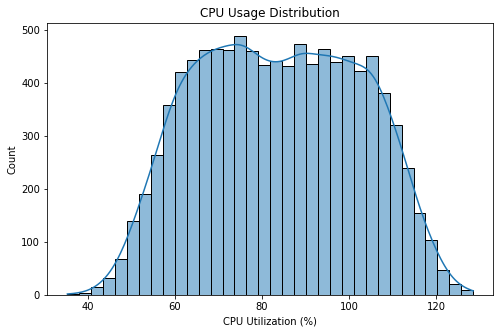

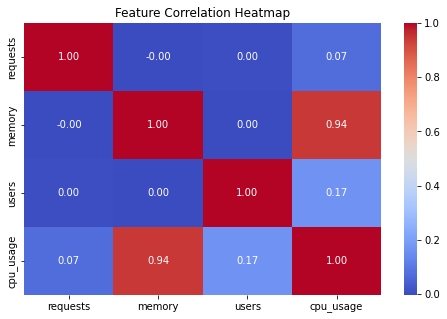

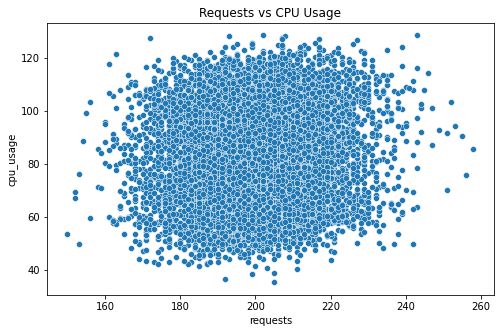

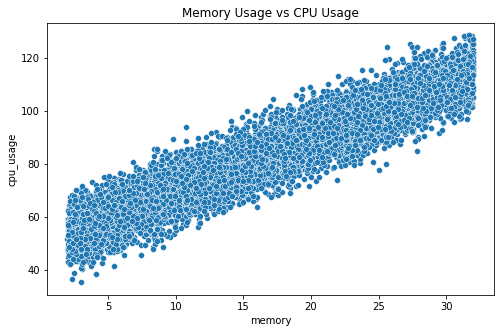

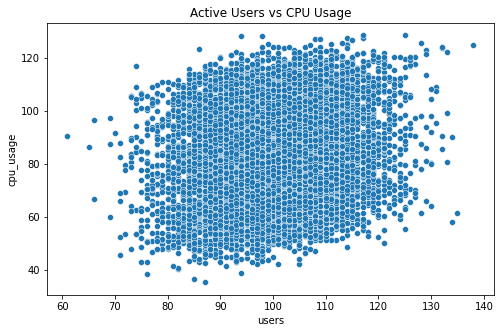

In [7]:

# CPU usage distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["cpu_usage"], kde=True)
plt.title("CPU Usage Distribution")
plt.xlabel("CPU Utilization (%)")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

# Requests vs CPU usage
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="requests", y="cpu_usage")
plt.title("Requests vs CPU Usage")
plt.show()

# Memory vs CPU usage
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="memory", y="cpu_usage")
plt.title("Memory Usage vs CPU Usage")
plt.show()

# Active users vs CPU usage
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="users", y="cpu_usage")
plt.title("Active Users vs CPU Usage")
plt.show()


In [8]:
# Step 4: Define input features (X) and target (Y)

In [9]:

# Input features
X = df[["requests", "memory", "users"]]

# Target variable
y = df["cpu_usage"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Features:
   requests     memory  users
0       175  14.377985     80
1       200   3.006782     92
2       186  27.010520    115
3       175  28.885040    106
4       190  30.501809     93

Target Variable:
0     74.239716
1     48.563785
2    100.966288
3    114.889753
4    110.342123
Name: cpu_usage, dtype: float64


In [10]:
# Step 5: Split the dataset

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (8000, 3)
Testing Data: (2000, 3)


In [12]:
# Step 6: Build and train Linear Regression model

In [13]:

model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Train model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [14]:
# Step 7: Make predictions

In [15]:

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual CPU Usage": y_test.values,
    "Predicted CPU Usage": y_pred
})

print(results.head(10))


   Actual CPU Usage  Predicted CPU Usage
0         70.043030            68.629022
1         66.118034            65.485365
2         92.951732            92.594615
3         75.616586            71.836053
4         88.362623            92.978180
5        111.749335           105.328497
6        116.997157           116.105051
7         85.335635            93.660078
8         61.098259            57.142037
9         98.462829            97.664649


In [16]:
# Step 8: Evaluate the model

In [17]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Model Evaluation Results
-------------------------
MAE: 4.0278649495852505
MSE: 25.767612953273208
RMSE: 5.076180941738898
R2 Score: 0.9243906661091715


In [18]:
# Step 9: Actual vs predicted visualization

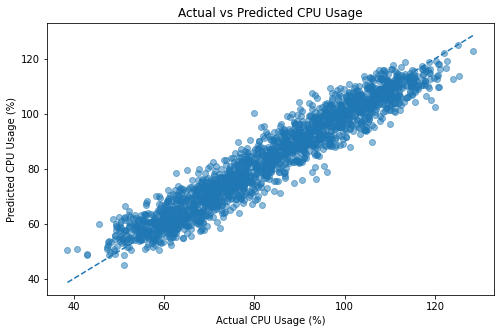

In [19]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual CPU Usage (%)")
plt.ylabel("Predicted CPU Usage (%)")
plt.title("Actual vs Predicted CPU Usage")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()


In [20]:
# Step 10: Feature coefficient interpretation

In [21]:

regressor = model.named_steps["regressor"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regressor.coef_
})

print("Feature Coefficients:")
print(coefficients)

print("\nIntercept:", regressor.intercept_)


Feature Coefficients:
    Feature  Coefficient
0  requests     1.361055
1    memory    17.309395
2     users     3.078834

Intercept: 83.8041850231193


In [22]:
# Step 11: Predict CPU usage for a new server scenario

In [23]:

new_server = pd.DataFrame({
    "requests": [200],
    "memory": [20],
    "users": [100]
})

predicted_cpu = model.predict(new_server)

print(
    "Predicted CPU Usage:",
    round(predicted_cpu[0], 2),
    "%"
)


Predicted CPU Usage: 89.95 %
